In [2]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [3]:
data = pd.read_csv("creditcard.csv")

print(data.head())
print(data["Class"].value_counts())


# 3. Separate features and labels
X = data.drop("Class", axis=1)
y = data["Class"]

print(X.shape)
print(y.shape)

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [3]:
X_train,X_test,y_train,y_test = train_test_split(
    X,y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train_normal = X_train[y_train==0]

X_fit,X_val = train_test_split(
    X_train_normal,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_fit = scaler.fit_transform(X_fit)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

model = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(16,activation="relu"),
    keras.layers.Dense(8,activation="relu"),
    keras.layers.Dense(16,activation="relu"),
    keras.layers.Dense(30, activation="linear")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 30)                  │             510 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,286 (5.02 KB)

 Trainable params: 1,286 (5.02 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
model.compile(
    optimizer = "adam",
    loss = "mse",
    metrics=["mae"]
)

In [5]:
history = model.fit(
    X_fit,X_fit,
    epochs=10,
    batch_size=256,
    validation_data=(X_val,X_val)
) 

Epoch 1/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.8349 - mae: 0.6130 - val_loss: 0.6821 - val_mae: 0.5555
Epoch 2/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.6388 - mae: 0.5375 - val_loss: 0.5983 - val_mae: 0.5209
Epoch 3/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5812 - mae: 0.5135 - val_loss: 0.5626 - val_mae: 0.5035
Epoch 4/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5555 - mae: 0.5008 - val_loss: 0.5473 - val_mae: 0.4994
Epoch 5/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.5399 - mae: 0.4936 - val_loss: 0.5291 - val_mae: 0.4885
Epoch 6/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.5286 - mae: 0.4876 - val_loss: 0.5193 - val_mae: 0.4839
Epoch 7/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5188 - mae: 0.4830 - val_loss: 0.5087 - val_mae: 0.4794
Epoch 8/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5082 - mae: 0.4793 - val_loss: 0.4981 - val_mae: 0.4749
Epoch 9/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - lo

In [6]:
val_prediction = model.predict(X_val)
val_errors = np.mean(
    np.square(X_val - val_prediction), axis=1
)

1422/1422 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step  


In [7]:
threshold = np.percentile(val_errors,99)
print("Threshold:", threshold)


Threshold: 2.5530179835341293


In [8]:
predictions = model.predict(X_test)
errors = np.mean(
    np.square(X_test-predictions), axis=1
)

y_pred = (errors>threshold).astype(int)

print("Predictions:", y_pred[:20])

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


1781/1781 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
Predictions: [0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0]

Confusion Matrix:
[[56246   618]
 [   15    83]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.12      0.85      0.21        98

    accuracy                           0.99     56962
   macro avg       0.56      0.92      0.60     56962
weighted avg       1.00      0.99      0.99     56962



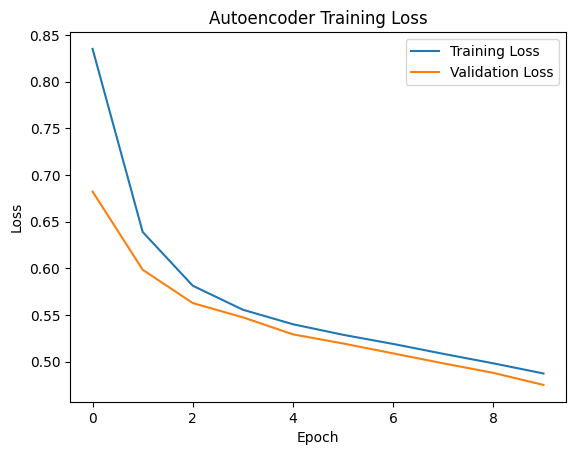

In [9]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
